# Q11: Logistic Regression – Student Placement
**Aim:** To predict student placement using logistic regression and evaluate the classifier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score, roc_auc_score, RocCurveDisplay)

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("11_Logistic_Placement.csv")
except FileNotFoundError:
    np.random.seed(42)
    cgpa = np.random.normal(7.5, 0.8, 50).clip(5, 10).round(2)
    apt = np.random.normal(65, 12, 50).clip(0, 100).round()
    tech = np.random.normal(70, 10, 50).clip(0, 100).round()
    z = (cgpa - 7.5) / 0.8 + 0.7 * (apt - 65) / 12 + 0.7 * (tech - 70) / 10
    df = pd.DataFrame({"Student_ID": [f"S{i:02d}" for i in range(1, 51)], "CGPA": cgpa, "Aptitude_Score": apt,
                       "Technical_Skill_Score": tech,
                       "Placement": np.where(np.random.rand(50) < 1 / (1 + np.exp(-z)), "Placed", "Not Placed")})
feats = ["CGPA", "Aptitude_Score", "Technical_Skill_Score"]
df.head()

,Student_ID,CGPA,Aptitude_Score,Technical_Skill_Score,Placement
0,S01,7.90,69.0,56.0,Not Placed
1,S02,7.39,60.0,66.0,Not Placed
2,S03,8.02,57.0,67.0,Not Placed
3,S04,8.72,72.0,62.0,Placed
4,S05,7.31,77.0,68.0,Placed


### 1. Distribution of placement outcomes

Placement
Not Placed    27
Placed        23
Name: count, dtype: int64


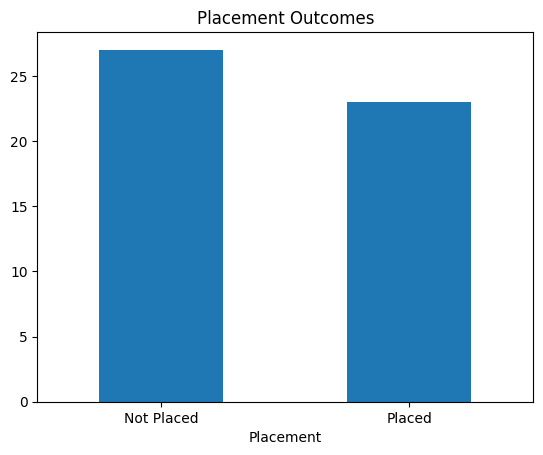

In [3]:
print(df["Placement"].value_counts())
df["Placement"].value_counts().plot(kind="bar", title="Placement Outcomes")
plt.xticks(rotation=0)
plt.show()

### 2. Encode placement as binary (1 = placed)

In [4]:
le = LabelEncoder()
df["Placed"] = le.fit_transform(df["Placement"])
print(dict(zip(le.classes_, range(len(le.classes_)))))

{'Not Placed': 0, 'Placed': 1}


Check the mapping: the placed class must be 1.

### 3. EDA: predictors vs placement

            CGPA  Aptitude_Score  Technical_Skill_Score
Placement                                              
Not Placed  6.98           63.04                  68.30
Placed      7.71           67.70                  71.26


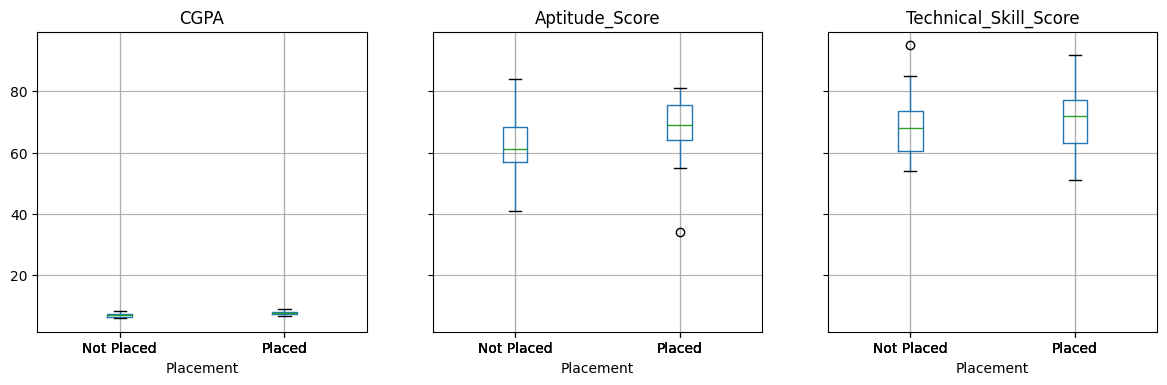

In [5]:
print(df.groupby("Placement")[feats].mean().round(2))
df.boxplot(column=feats, by="Placement", layout=(1, 3), figsize=(14, 4))
plt.suptitle("")
plt.show()

### 4. Stratified 80:20 split

In [6]:
X, y = df[feats], df["Placed"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", y_train.value_counts().to_dict(), " Test:", y_test.value_counts().to_dict())

Train: {0: 22, 1: 18}  Test: {0: 5, 1: 5}


### 5. Standardize (fit on training data only)

In [7]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

### 6. Logistic regression model

In [8]:
model = LogisticRegression().fit(X_train_s, y_train)
print("Intercept:", round(model.intercept_[0], 3))
print(pd.Series(model.coef_[0], index=feats).round(3))

Intercept: -0.235
CGPA                     0.795
Aptitude_Score           0.519
Technical_Skill_Score    0.515
dtype: float64


### 7. Confusion matrix and metrics

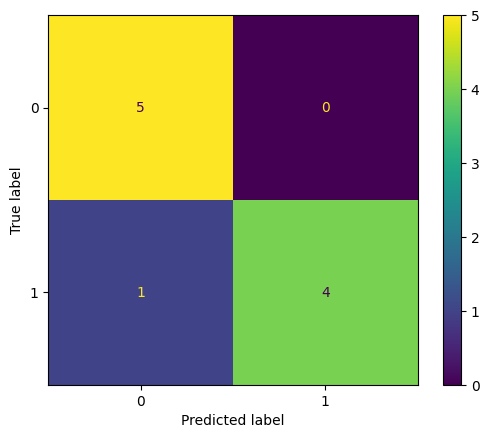

,0
Accuracy,0.900
Precision,1.000
Recall,0.800
Specificity,1.000
F1,0.889
Balanced_Accuracy,0.900


In [9]:
y_pred = model.predict(X_test_s)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()
pd.Series({"Accuracy": accuracy_score(y_test, y_pred),
           "Precision": precision_score(y_test, y_pred, zero_division=0),
           "Recall": recall_score(y_test, y_pred),
           "Specificity": tn / (tn + fp),
           "F1": f1_score(y_test, y_pred, zero_division=0),
           "Balanced_Accuracy": balanced_accuracy_score(y_test, y_pred)}).round(3)

### 8. ROC curve and AUC

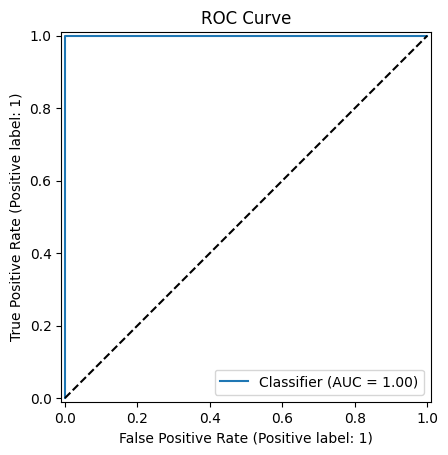

AUC = 1.0


In [10]:
prob = model.predict_proba(X_test_s)[:, 1]
RocCurveDisplay.from_predictions(y_test, prob)
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curve")
plt.show()
print("AUC =", round(roc_auc_score(y_test, prob), 3))

### 9. Thresholds 0.3, 0.5, 0.7 (chosen on validation data)

In [11]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train, test_size=0.25, stratify=y_train, random_state=42)
val_prob = LogisticRegression().fit(X_tr, y_tr).predict_proba(X_val)[:, 1]
rows = []
for t in [0.3, 0.5, 0.7]:
    p = (val_prob >= t).astype(int)
    rows.append([t, accuracy_score(y_val, p), precision_score(y_val, p, zero_division=0),
                 recall_score(y_val, p), f1_score(y_val, p, zero_division=0)])
th = pd.DataFrame(rows, columns=["Threshold", "Accuracy", "Precision", "Recall", "F1"]).round(3)
best = th.loc[th["F1"].idxmax(), "Threshold"]
print(th)
print("Best threshold on validation (highest F1):", best)

   Threshold  Accuracy  Precision  Recall     F1
0        0.3       0.5      0.444    1.00  0.615
1        0.5       0.7      0.667    0.50  0.571
2        0.7       0.7      1.000    0.25  0.400
Best threshold on validation (highest F1): 0.3


In [12]:
y_best = (prob >= best).astype(int)
print(f"Test at threshold {best}: Accuracy = {accuracy_score(y_test, y_best):.3f}, F1 = {f1_score(y_test, y_best, zero_division=0):.3f}")

Test at threshold 0.3: Accuracy = 1.000, F1 = 1.000


### 10. Odds ratios

In [13]:
pd.Series(np.exp(model.coef_[0]), index=feats, name="Odds_Ratio (per 1 SD increase)").round(3)

,Odds_Ratio (per 1 SD increase)
CGPA,2.215
Aptitude_Score,1.680
Technical_Skill_Score,1.674


Odds ratio > 1 → higher value increases the odds of placement; < 1 → decreases.

### 11. False positives and false negatives

In [14]:
out = df.loc[X_test.index, ["Student_ID"] + feats + ["Placement"]]
out["Prob_Placed"] = prob.round(3)
out["Error"] = np.where((y_pred == 1) & (y_test == 0), "False Positive",
               np.where((y_pred == 0) & (y_test == 1), "False Negative", "Correct"))
out[out["Error"] != "Correct"]

,Student_ID,CGPA,Aptitude_Score,Technical_Skill_Score,Placement,Prob_Placed,Error
27,S28,7.8,61.0,64.0,Placed,0.469,False Negative


- **False positive:** predicted placed but not placed → student may get no extra support and stay unprepared.
- **False negative:** predicted not placed but actually placed → wasted training effort, or a capable student is under-rated.

**Result:** A logistic regression model was built and evaluated with confusion matrix, metrics, ROC-AUC, threshold tuning and odds ratios.